# AI651 – Deep Learning for Space, Time and Graphs
# Assignment 3

Syed Obaidullah Hassan Chishti - 25280049

### Question 7 - Reproducibility and Reporting

# Imports

In [1]:
import os
import sys
import platform
import numpy as np
import pandas as pd
import torch
from IPython.display import Image, display

/home/obaid/miniconda3/envs/edge_devices/lib/python3.11/site-packages/torch/cuda/__init__.py:61: FutureWarning: The pynvml package is deprecated. Please install nvidia-ml-py instead. If you did not install pynvml directly, please report this to the maintainers of the package that installed pynvml for you.
  import pynvml  # type: ignore[import]


## Check and download the dataset

In [2]:
import kagglehub

DATA_DIR = kagglehub.dataset_download("liuxu77/largest")
print("Dataset directory:", DATA_DIR)
print("Files:", sorted(os.listdir(DATA_DIR)))

# Sanity check that the files we need are present
for f in ["ca_meta.csv", "ca_rn_adj.npy", "ca_his_raw_2020.h5", "ca_his_raw_2021.h5"]:
    path = os.path.join(DATA_DIR, f)
    print(("OK  " if os.path.exists(path) else "MISSING "), f)

Dataset directory: /home/obaid/.cache/kagglehub/datasets/liuxu77/largest/versions/1
Files: ['ca_his_raw_2017.h5', 'ca_his_raw_2018.h5', 'ca_his_raw_2019.h5', 'ca_his_raw_2020.h5', 'ca_his_raw_2021.h5', 'ca_meta.csv', 'ca_rn_adj.npy']
OK   ca_meta.csv
OK   ca_rn_adj.npy
OK   ca_his_raw_2020.h5
OK   ca_his_raw_2021.h5


## Hardware and software environment

In [3]:
print("=== Hardware ===")
print("OS           :", platform.platform())
print("Processor    :", platform.processor() or "n/a")
print("Logical CPUs :", os.cpu_count())
try:
    gb = os.sysconf("SC_PHYS_PAGES") * os.sysconf("SC_PAGE_SIZE") / 1e9
    print(f"RAM          : {gb:.1f} GB")
except Exception:
    print("RAM          : n/a")

print("GPU          :", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU only")

print("\n=== Software ===")
print("Python :", sys.version.split()[0])
print("numpy  :", np.__version__)
print("pandas :", pd.__version__)
print("torch  :", torch.__version__, "| CUDA available:", torch.cuda.is_available())

=== Hardware ===
OS           : Linux-7.0.0-43-generic-x86_64-with-glibc2.39
Processor    : x86_64
Logical CPUs : 16
RAM          : 16.4 GB
GPU          : CPU only

=== Software ===
Python : 3.11.16
numpy  : 2.2.6
pandas : 3.0.5
torch  : 2.11.0+cpu | CUDA available: False


## Experiment configuration

All models share this configuration. These are the hyperparameters, seed, and splits to report.

In [4]:
config = {
    "dataset": "LargeST San Diego (District 11), 716 sensors",
    "years": "2020 and 2021",
    "sampling": "15-minute (averaged from 5-minute)",
    "input_history": "8 timestamps (2 hours)",
    "prediction_horizon": "4 timestamps (1 hour)",
    "train_split": "Jan-Dec 2020",
    "val_split": "Jan-Mar 2021",
    "test_split": "Apr-Dec 2021",
    "normalization": "z-score, training statistics only",
    "hidden_dim": 32,
    "embedding_dim_de": 16,
    "topk_neighbours": 20,
    "epochs": 10,
    "batch_size": 64,
    "optimizer": "Adam",
    "learning_rate": 1e-3,
    "loss": "MAE (L1)",
    "random_seed": 2023,
}

for k, v in config.items():
    print(f"{k:22s}: {v}")

dataset               : LargeST San Diego (District 11), 716 sensors
years                 : 2020 and 2021
sampling              : 15-minute (averaged from 5-minute)
input_history         : 8 timestamps (2 hours)
prediction_horizon    : 4 timestamps (1 hour)
train_split           : Jan-Dec 2020
val_split             : Jan-Mar 2021
test_split            : Apr-Dec 2021
normalization         : z-score, training statistics only
hidden_dim            : 32
embedding_dim_de      : 16
topk_neighbours       : 20
epochs                : 10
batch_size            : 64
optimizer             : Adam
learning_rate         : 0.001
loss                  : MAE (L1)
random_seed           : 2023


## Final comparison table

In [5]:
if os.path.exists("results_q6.csv"):
    results = pd.read_csv("results_q6.csv", keep_default_na=False)
    print(results.to_string(index=False))
else:
    print("results_q6.csv not found. Run Question 6 to generate the comparison table.")

        Model Adjacency       MAE      RMSE  Training time (s)
Temporal-only      None 21.527466 34.742462          72.139427
        STGNN     Fixed 48.491119 79.111206          75.531047
        STGNN  Adaptive 26.890320 44.241806          86.260582
        STGNN    Hybrid 26.539202 41.781460         104.096114


## Required visualizations

Road-distance adjacency (Q3b)


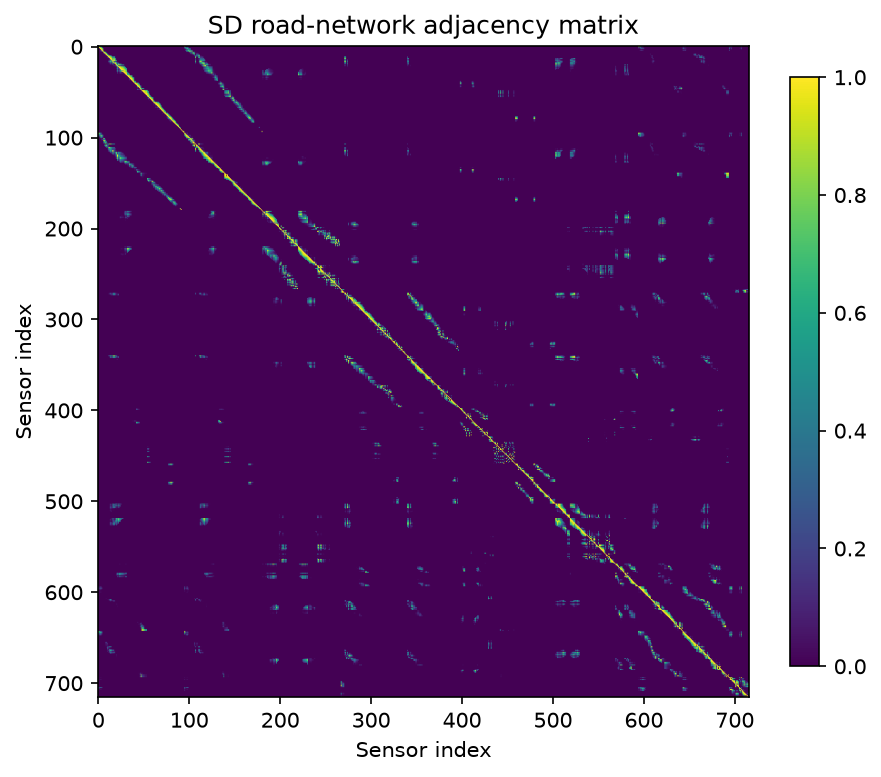

Learned adjacency (Q5b)


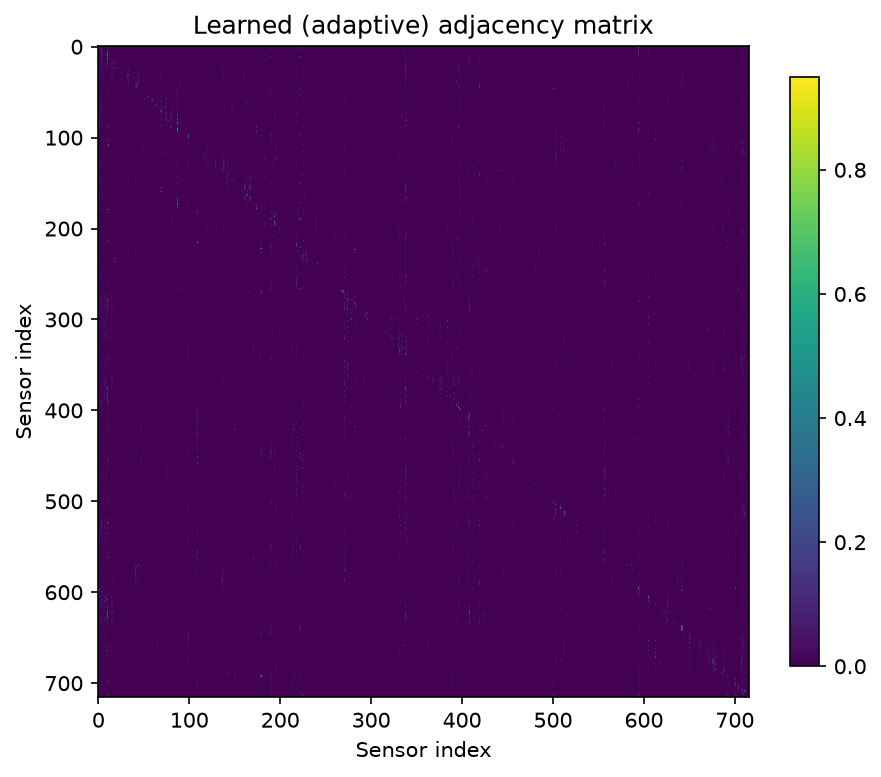

Road vs learned graph (Q6b)


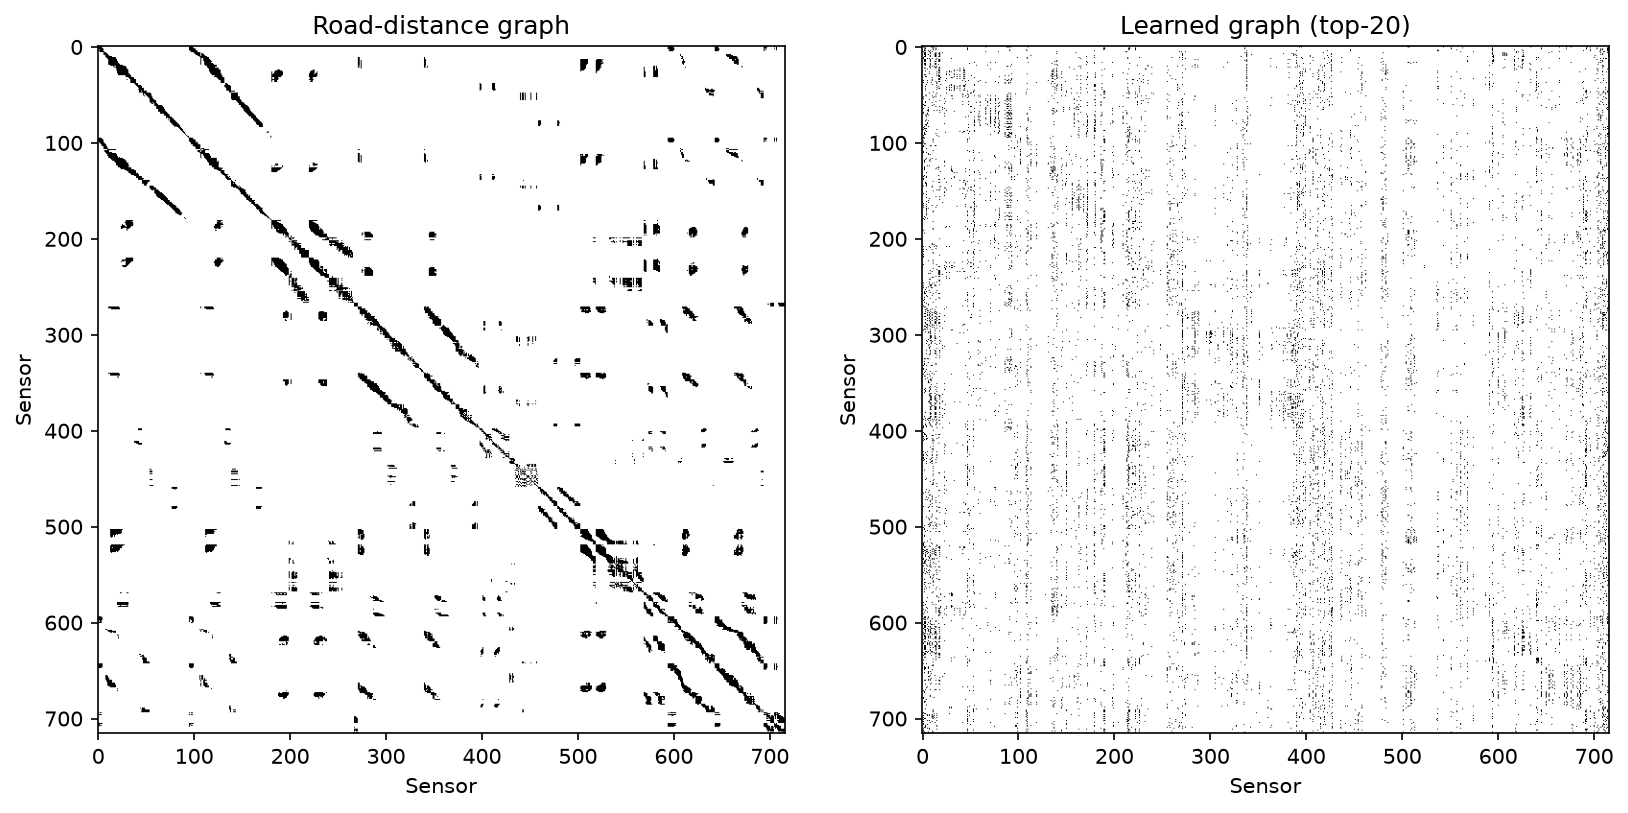

Predicted vs actual, 3 sensors (Q6a)


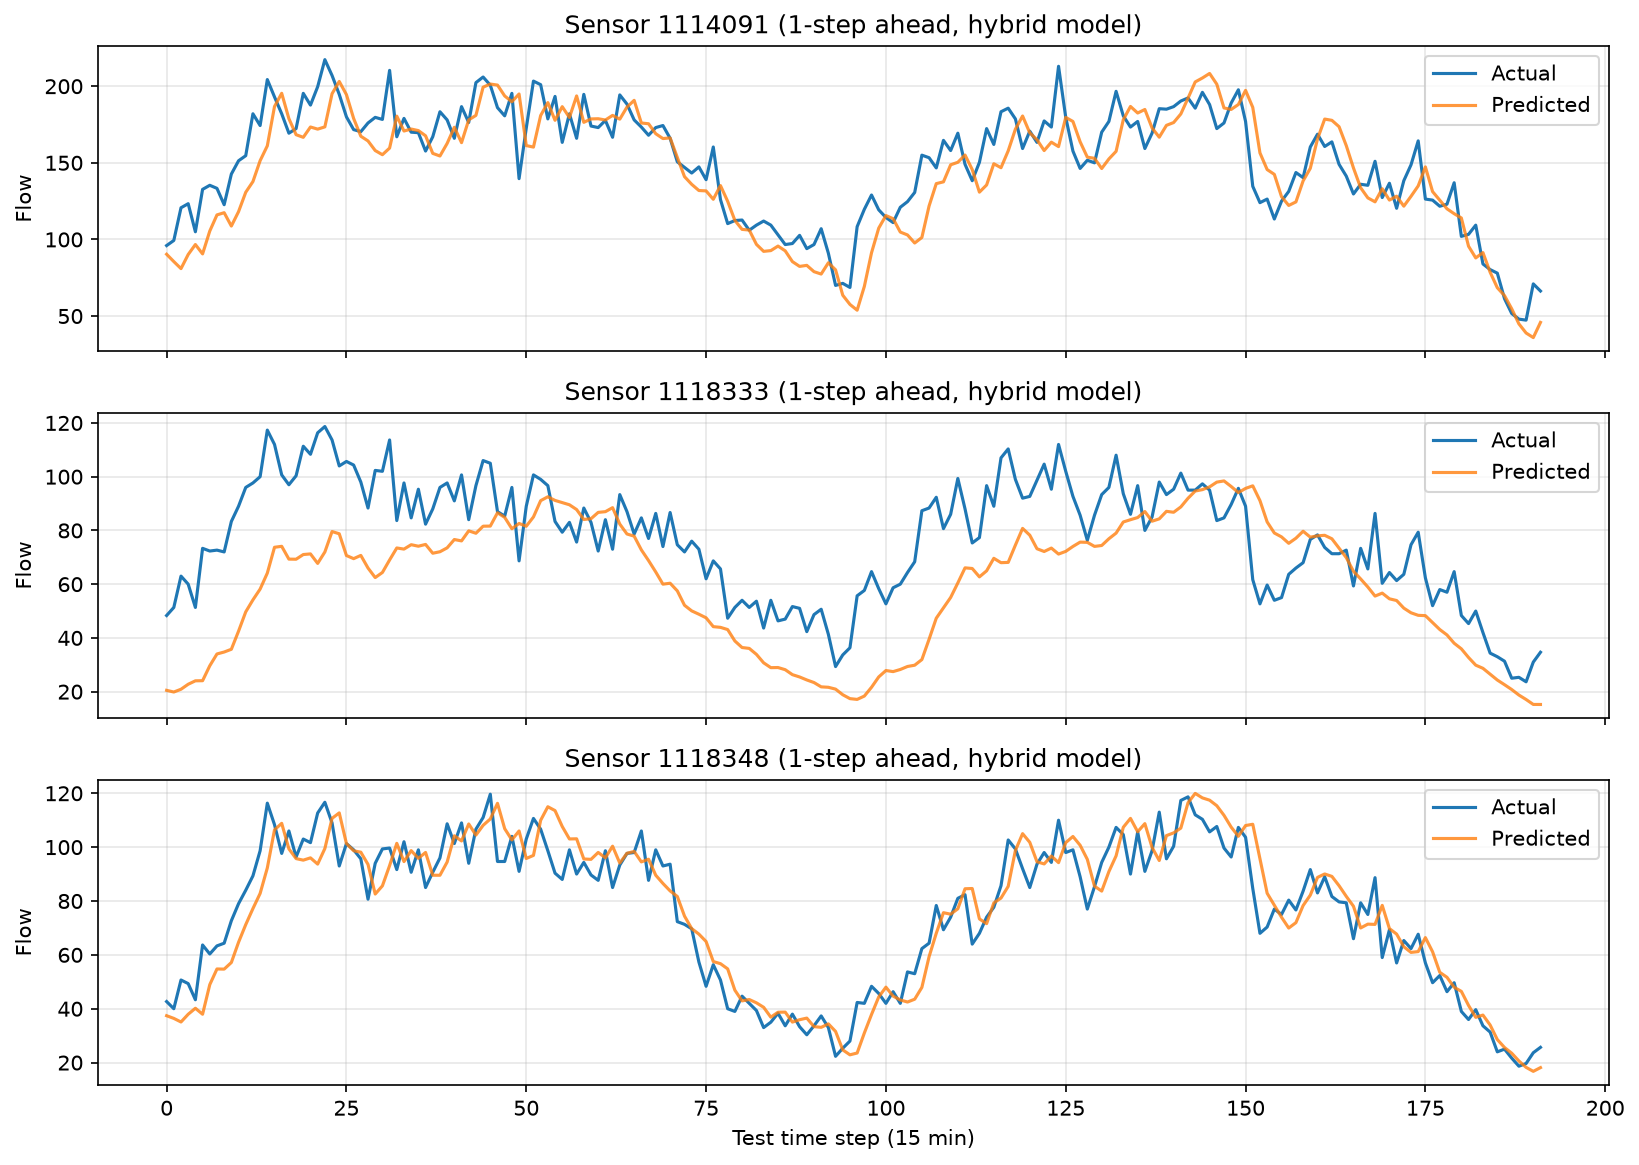

In [6]:
figures = [
    ("figures/q3b_adjacency_heatmap.png", "Road-distance adjacency (Q3b)"),
    ("figures/q5b_learned_adjacency.png", "Learned adjacency (Q5b)"),
    ("figures/q6b_road_vs_learned.png",   "Road vs learned graph (Q6b)"),
    ("figures/q6a_pred_vs_actual.png",    "Predicted vs actual, 3 sensors (Q6a)"),
]

for path, caption in figures:
    if os.path.exists(path):
        print(caption)
        display(Image(filename=path))
    else:
        print(f"[missing] {path} - run the notebook that produces it")